# New York County Heat Maps: Median Age and Median Household Income

**Data source:** U.S. Census Bureau, American Community Survey (ACS) 5-Year Estimates, 2024 (survey responses collected 2020 through 2024)

**Variables:**
- `B01002_001E` = Median age
- `B19013_001E` = Median household income (in dollars)

**Steps:**
1. Pull the data for every New York county from the Census API
2. Clean it up
3. Draw two heat maps, one for income and one for age

## Step 1: Load the libraries

In [1]:
import requests               # lets us download data from the internet
import pandas as pd           # lets us work with data in tables
import plotly.express as px   # lets us draw maps

## Step 2: Pull the Census data for each New York county

In [2]:
# my Census API key (paste your own key between the quotes; it is left out here so it is not public)
api_key = "PASTE_YOUR_CENSUS_API_KEY_HERE"

# New York's state code (every state has a 2-digit number called a FIPS code; New York is 36)
state_code = "36"

# the web address for the 2024 ACS 5-year data (covers 2020-2024; newest available)
url = "https://api.census.gov/data/2024/acs/acs5"

# what we are asking the Census for
params = {
    "get": "NAME,B01002_001E,B19013_001E",  # county name, median age, median household income
    "for": "county:*",                      # every county...
    "in": "state:" + state_code,            # ...in New York
    "key": api_key                          # our key
}

# send the request to the Census website
response = requests.get(url, params=params)

# turn the answer into a Python list (the first row is the column names)
data = response.json()

# put the data into a table, using the first row as the column names
df = pd.DataFrame(data[1:], columns=data[0])

# look at the first 5 rows
df.head()

,NAME,B01002_001E,B19013_001E,state,county
0,"Albany County, New York",38.4,85333,36,001
1,"Allegany County, New York",38.7,62869,36,003
2,"Bronx County, New York",36.0,48676,36,005
3,"Broome County, New York",39.2,62616,36,007
4,"Cattaraugus County, New York",42.8,59540,36,009


## Step 3: Clean up the data

In [3]:
# give the columns easier names
df = df.rename(columns={"B01002_001E": "median_age", "B19013_001E": "median_income"})

# the Census sends numbers as text, so turn them into real numbers
df["median_age"] = df["median_age"].astype(float)
df["median_income"] = df["median_income"].astype(int)

# make the 5-digit county code (state code + county code) that the map needs to match counties
df["fips"] = df["state"] + df["county"]

# remove ", New York" from the county names so they look cleaner
df["NAME"] = df["NAME"].str.replace(", New York", "")

# show how many counties we got (New York has 62)
print("Number of counties:", len(df))

# show the table
df

Number of counties: 62


,NAME,median_age,median_income,state,county,fips
0,Albany County,38.4,85333,36,001,36001
1,Allegany County,38.7,62869,36,003,36003
2,Bronx County,36.0,48676,36,005,36005
3,Broome County,39.2,62616,36,007,36007
4,Cattaraugus County,42.8,59540,36,009,36009
...,...,...,...,...,...,...
57,Washington County,45.4,73495,36,115,36115
58,Wayne County,43.6,74506,36,117,36117
59,Westchester County,41.8,118976,36,119,36119
60,Wyoming County,43.3,69110,36,121,36121


## Step 4: Download the county shapes for the map

In [4]:
# this file has the outline (shape) of every U.S. county, labeled by its 5-digit county code
shapes_url = "https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json"

# download the county shapes
counties = requests.get(shapes_url).json()

# keep only New York's counties (their codes start with "36") so the file stays small
ny_shapes = []                                   # start with an empty list
for shape in counties["features"]:               # go through every county shape one at a time
    if shape["id"].startswith(state_code):       # if the county code starts with 36...
        ny_shapes.append(shape)                  # ...add it to our list
counties["features"] = ny_shapes                 # replace the full list with just New York

# check that we have 62 shapes
print("Number of county shapes:", len(counties["features"]))

Number of county shapes: 62


## Step 5: Median Household Income heat map

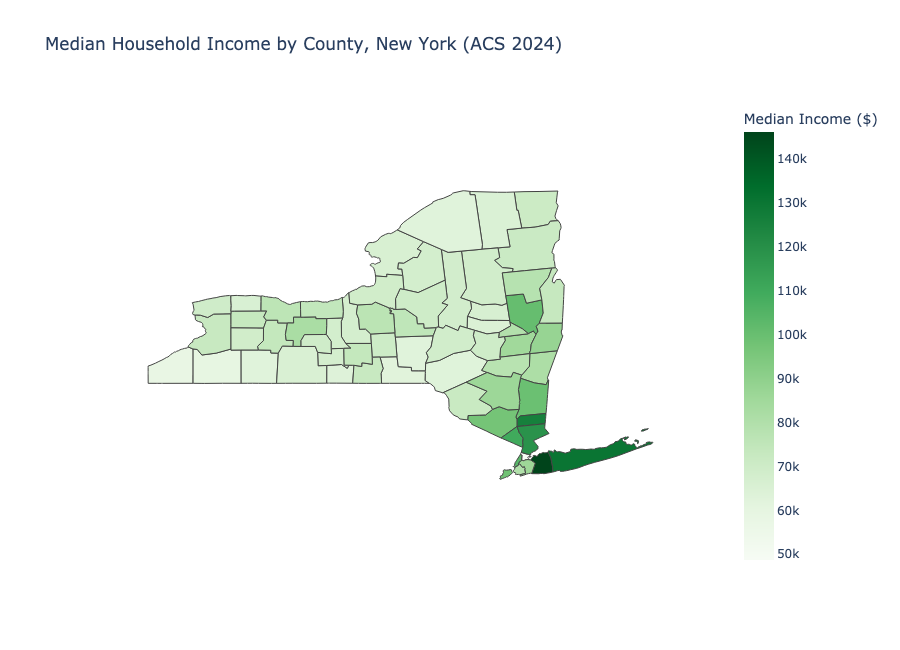

In [5]:
# draw the map: each county is colored by its median income
income_map = px.choropleth(
    df,                                    # our data table
    geojson=counties,                      # the county shapes
    locations="fips",                      # the column that matches each row to a county shape
    color="median_income",                 # the column that decides the color
    color_continuous_scale="Greens",       # light green = lower income, dark green = higher income
    hover_name="NAME",                     # show the county name when you hover over it
    labels={"median_income": "Median Income ($)"},  # nicer label for the color bar
    title="Median Household Income by County, New York (ACS 2024)"
)

# zoom the map in on New York only
income_map.update_geos(fitbounds="locations", visible=False)

# show the interactive map (you can hover over counties in Jupyter)
# "notebook_connected" loads the map tools from the internet, which keeps this file small enough for GitHub
income_map.show("notebook_connected")

# also show it as a plain picture so it is visible on GitHub
income_map.show("png", width=900, height=650)

## Step 6: Median Age heat map

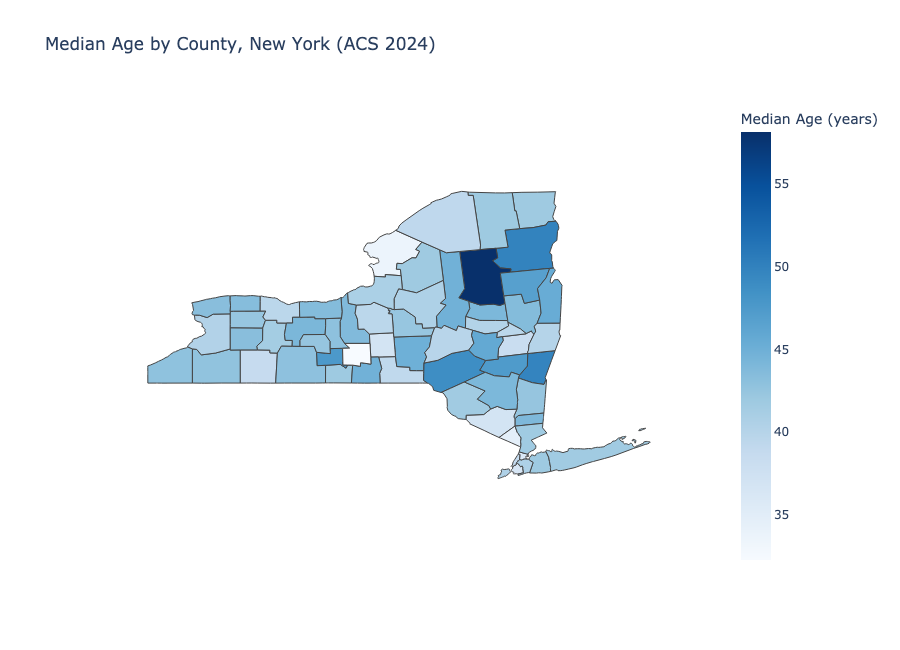

In [6]:
# draw the map: each county is colored by its median age
age_map = px.choropleth(
    df,                                    # our data table
    geojson=counties,                      # the county shapes
    locations="fips",                      # the column that matches each row to a county shape
    color="median_age",                    # the column that decides the color
    color_continuous_scale="Blues",        # light blue = younger, dark blue = older
    hover_name="NAME",                     # show the county name when you hover over it
    labels={"median_age": "Median Age (years)"},  # nicer label for the color bar
    title="Median Age by County, New York (ACS 2024)"
)

# zoom the map in on New York only
age_map.update_geos(fitbounds="locations", visible=False)

# show the interactive map (you can hover over counties in Jupyter)
# "notebook_connected" loads the map tools from the internet, which keeps this file small enough for GitHub
age_map.show("notebook_connected")

# also show it as a plain picture so it is visible on GitHub
age_map.show("png", width=900, height=650)

## Step 7: Quick look at the highest and lowest counties

In [7]:
# sort counties from highest to lowest income and show the top 5 and bottom 5
print("Highest median income:")
print(df.sort_values("median_income", ascending=False)[["NAME", "median_income"]].head(5))
print()
print("Lowest median income:")
print(df.sort_values("median_income")[["NAME", "median_income"]].head(5))
print()

# do the same for age
print("Oldest median age:")
print(df.sort_values("median_age", ascending=False)[["NAME", "median_age"]].head(5))
print()
print("Youngest median age:")
print(df.sort_values("median_age")[["NAME", "median_age"]].head(5))

Highest median income:
                  NAME  median_income
29       Nassau County         146202
51      Suffolk County         130686
39       Putnam County         126257
59  Westchester County         118976
43     Rockland County         109959

Lowest median income:
                   NAME  median_income
2          Bronx County          48676
6     Chautauqua County          58351
4    Cattaraugus County          59540
3         Broome County          62616
44  St. Lawrence County          62850

Oldest median age:
               NAME  median_age
20  Hamilton County        58.1
15     Essex County        49.9
10  Columbia County        49.8
12  Delaware County        48.8
48  Schuyler County        47.6

Youngest median age:
                NAME  median_age
54   Tompkins County        32.3
22  Jefferson County        33.7
43   Rockland County        34.8
2       Bronx County        36.0
23      Kings County        36.5
